In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
import pickle
import os
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [4]:
df=pd.read_csv("PriorityDataset_1.csv")
df

,Vehicle ID,Speed (km/h),"GPS Location (Lat, Long)",Signal Strength (dBm),Packet Delay (ms),Congestion Level (%),Available Bandwidth (MHz),Contention Window Size,RSU Connection (Yes/No),Traffic Density (vehicles/km²),Priority Level (1-5)
0,V0103,23,"(-1.4919, 104.766)",-55,34,57,22,46,Yes,19,4
1,V0436,88,"(-29.2844, 139.1703)",-52,9,61,14,41,Yes,93,2
2,V0861,37,"(-30.4282, -117.4462)",-79,17,21,35,46,Yes,23,1
3,V0271,90,"(11.9613, -114.2802)",-85,25,76,24,33,Yes,11,4
4,V0107,117,"(8.7171, 2.9953)",-72,23,77,48,42,Yes,38,5
...,...,...,...,...,...,...,...,...,...,...,...
4995,V0290,57,"(-48.8052, 56.5931)",-83,34,12,24,44,Yes,32,1
4996,V0295,35,"(-9.8659, -96.0506)",-52,50,61,43,43,No,40,2
4997,V0451,102,"(79.5828, 175.25)",-64,26,80,12,13,Yes,27,1
4998,V0904,66,"(88.6695, 53.1574)",-71,23,75,6,36,Yes,86,2


In [5]:
df['Priority Level (1-5)'].unique()

array([4, 2, 1, 5, 3], dtype=int64)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   Vehicle ID                      5000 non-null   object
 1   Speed (km/h)                    5000 non-null   int64 
 2   GPS Location (Lat, Long)        5000 non-null   object
 3   Signal Strength (dBm)           5000 non-null   int64 
 4   Packet Delay (ms)               5000 non-null   int64 
 5   Congestion Level (%)            5000 non-null   int64 
 6   Available Bandwidth (MHz)       5000 non-null   int64 
 7   Contention Window Size          5000 non-null   int64 
 8   RSU Connection (Yes/No)         5000 non-null   object
 9   Traffic Density (vehicles/km²)  5000 non-null   int64 
 10  Priority Level (1-5)            5000 non-null   int64 
dtypes: int64(8), object(3)
memory usage: 429.8+ KB


In [7]:
df.isnull().sum()

Vehicle ID                        0
Speed (km/h)                      0
GPS Location (Lat, Long)          0
Signal Strength (dBm)             0
Packet Delay (ms)                 0
Congestion Level (%)              0
Available Bandwidth (MHz)         0
Contention Window Size            0
RSU Connection (Yes/No)           0
Traffic Density (vehicles/km²)    0
Priority Level (1-5)              0
dtype: int64

In [8]:
df.duplicated().sum()

4011

In [9]:
df.nunique()

Vehicle ID                        989
Speed (km/h)                      101
GPS Location (Lat, Long)          989
Signal Strength (dBm)              41
Packet Delay (ms)                  46
Congestion Level (%)              101
Available Bandwidth (MHz)          46
Contention Window Size             41
RSU Connection (Yes/No)             2
Traffic Density (vehicles/km²)     91
Priority Level (1-5)                5
dtype: int64

In [10]:
x = df.drop(['Priority Level (1-5)'],axis=1)
x

,Vehicle ID,Speed (km/h),"GPS Location (Lat, Long)",Signal Strength (dBm),Packet Delay (ms),Congestion Level (%),Available Bandwidth (MHz),Contention Window Size,RSU Connection (Yes/No),Traffic Density (vehicles/km²)
0,V0103,23,"(-1.4919, 104.766)",-55,34,57,22,46,Yes,19
1,V0436,88,"(-29.2844, 139.1703)",-52,9,61,14,41,Yes,93
2,V0861,37,"(-30.4282, -117.4462)",-79,17,21,35,46,Yes,23
3,V0271,90,"(11.9613, -114.2802)",-85,25,76,24,33,Yes,11
4,V0107,117,"(8.7171, 2.9953)",-72,23,77,48,42,Yes,38
...,...,...,...,...,...,...,...,...,...,...
4995,V0290,57,"(-48.8052, 56.5931)",-83,34,12,24,44,Yes,32
4996,V0295,35,"(-9.8659, -96.0506)",-52,50,61,43,43,No,40
4997,V0451,102,"(79.5828, 175.25)",-64,26,80,12,13,Yes,27
4998,V0904,66,"(88.6695, 53.1574)",-71,23,75,6,36,Yes,86


In [11]:
y = df['Priority Level (1-5)']
y

0       4
1       2
2       1
3       4
4       5
       ..
4995    1
4996    2
4997    1
4998    2
4999    4
Name: Priority Level (1-5), Length: 5000, dtype: int64

<Axes: xlabel='Priority Level (1-5)', ylabel='count'>

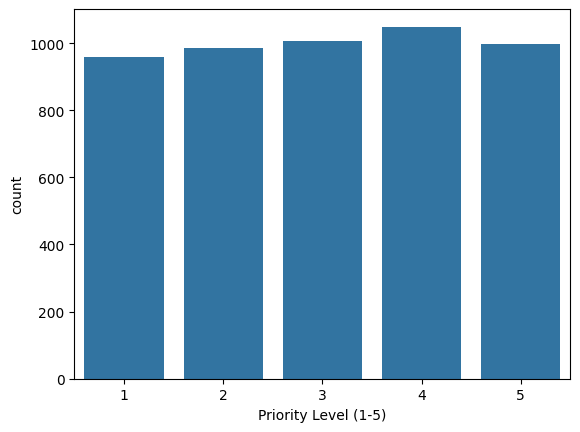

In [12]:
sns.countplot(x=y)

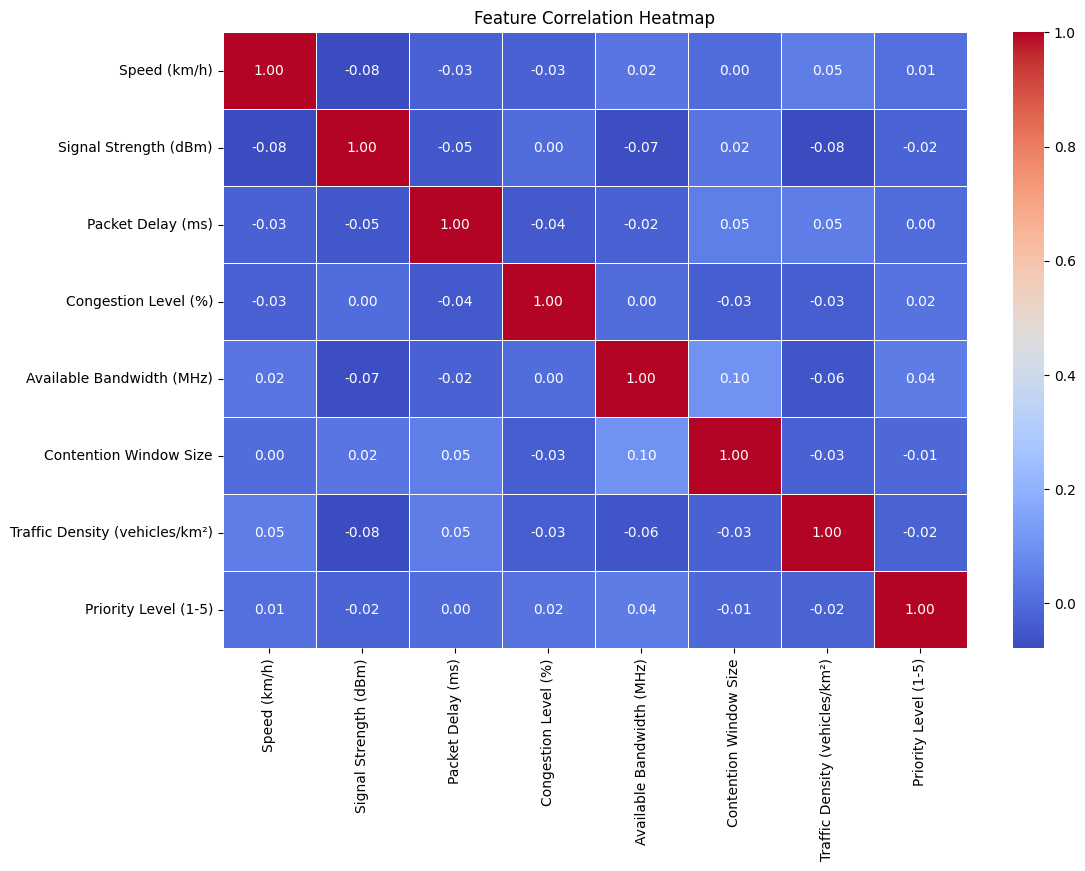

In [14]:
plt.figure(figsize=(12, 8))

numeric_df = df.select_dtypes(include=['number'])

sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

plt.title("Feature Correlation Heatmap")
plt.show()


In [15]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size = 0.2, random_state = 42)

In [16]:
x_train.shape

(4000, 10)

In [17]:
x_test.shape

(1000, 10)

In [18]:
y_train.shape

(4000,)

In [19]:
y_test.shape

(1000,)

In [20]:
labels = ['1','2','3','4','5']

In [21]:
precision = []
recall = []
fscore = []
accuracy = []

#function to calculate various metrics such as accuracy, precision etc
def PerformanceMetrics(algorithm, predict, testY):
    testY = testY.astype('int')
    predict = predict.astype('int')
    p = precision_score(testY, predict,average='macro') * 100
    r = recall_score(testY, predict,average='macro') * 100
    f = f1_score(testY, predict,average='macro') * 100
    a = accuracy_score(testY,predict)*100 
    accuracy.append(a)
    precision.append(p)
    recall.append(r)
    fscore.append(f)
    print(algorithm+' Accuracy    : '+str(a))
    print(algorithm+' Precision   : '+str(p))
    print(algorithm+' Recall      : '+str(r))
    print(algorithm+' FSCORE      : '+str(f))
    print(f"\n{algorithm} Classification Report:\n")
    print(classification_report(testY, predict, target_names=labels))
    conf_matrix = confusion_matrix(testY, predict) 
    plt.figure(figsize =(5, 5)) 
    ax = sns.heatmap(conf_matrix, xticklabels = labels, yticklabels = labels, annot = True, cmap="Blues" ,fmt ="g");
    ax.set_ylim([0,len(labels)])
    plt.title(algorithm+" Confusion matrix") 
    plt.ylabel('True class') 
    plt.xlabel('Predicted class') 
    plt.show()


Loaded existing Logistic Regression model.
Logistic Regression Accuracy    : 25.6
Logistic Regression Precision   : 26.733124220129046
Logistic Regression Recall      : 25.87867874090805
Logistic Regression FSCORE      : 25.03716898754671

Logistic Regression Classification Report:

              precision    recall  f1-score   support

           1       0.29      0.16      0.21       200
           2       0.31      0.16      0.21       214
           3       0.29      0.34      0.31       205
           4       0.25      0.30      0.27       205
           5       0.21      0.34      0.26       176

    accuracy                           0.26      1000
   macro avg       0.27      0.26      0.25      1000
weighted avg       0.27      0.26      0.25      1000



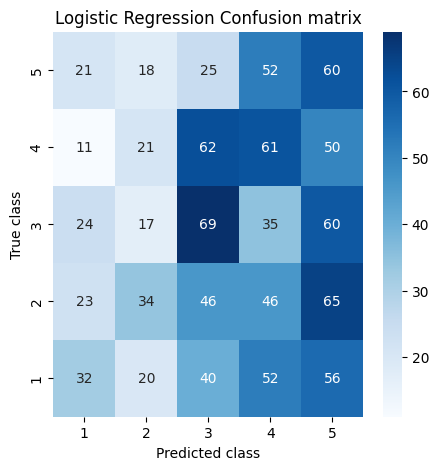

In [25]:
from sklearn.linear_model import LogisticRegression
model_path = 'logistic_regression.pkl'
def encode_dataframe(df):
    df = df.copy()
    for col in df.select_dtypes(include=['object']):
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
    return df

x_train_encoded = encode_dataframe(x_train)
x_test_encoded  = encode_dataframe(x_test)
load_model = False
if os.path.exists(model_path):
    try:
        logistic_regression = joblib.load(model_path)
        _ = logistic_regression.predict(x_test_encoded)
        load_model = True
        print("Loaded existing Logistic Regression model.")
    except:
        print("Model mismatch detected. Retraining model...")
        load_model = False
if not load_model:
    logistic_regression = LogisticRegression(max_iter=1000)
    logistic_regression.fit(x_train_encoded, y_train)
    joblib.dump(logistic_regression, model_path)
    print("Logistic Regression trained and model saved.")
predict = logistic_regression.predict(x_test_encoded)
PerformanceMetrics("Logistic Regression", predict, y_test)


Loaded existing KNN model.
KNeighborsClassifier Accuracy    : 18.5
KNeighborsClassifier Precision   : 18.845689372187096
KNeighborsClassifier Recall      : 18.535216652506374
KNeighborsClassifier FSCORE      : 18.562982911248177

KNeighborsClassifier Classification Report:

              precision    recall  f1-score   support

           1       0.16      0.15      0.16       200
           2       0.17      0.17      0.17       214
           3       0.25      0.20      0.22       205
           4       0.20      0.20      0.20       205
           5       0.15      0.20      0.17       176

    accuracy                           0.18      1000
   macro avg       0.19      0.19      0.19      1000
weighted avg       0.19      0.18      0.19      1000



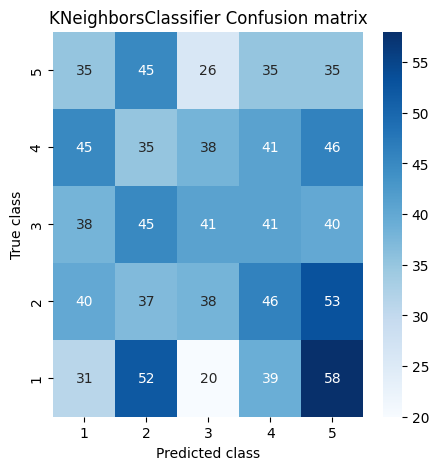

In [29]:
from sklearn.neighbors import KNeighborsClassifier
model_path = 'KNeighborsClassifier.pkl'
def encode_dataframe(df):
    df = df.copy()
    for col in df.select_dtypes(include=['object']):
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
    return df

x_train_encoded = encode_dataframe(x_train)
x_test_encoded  = encode_dataframe(x_test)
if os.path.exists(model_path):
    try:
        knn_model = joblib.load(model_path)
        _ = knn_model.predict(x_test_encoded)      # try prediction to check feature match
        load_model = True
        print("Loaded existing KNN model.")
    except:
        print("KNN model mismatch → Retraining...")
        load_model = False
if not load_model:
    knn_model = KNeighborsClassifier()
    knn_model.fit(x_train_encoded, y_train)
    joblib.dump(knn_model, model_path)
    print("KNN model trained and saved.")
predict = knn_model.predict(x_test_encoded)
PerformanceMetrics("KNeighborsClassifier", predict, y_test)


Decision Tree model mismatch → Retraining...
Decision Tree model trained and saved.
DecisionTreeClassifier Accuracy    : 65.3
DecisionTreeClassifier Precision   : 65.40462089712105
DecisionTreeClassifier Recall      : 65.48147419027292
DecisionTreeClassifier FSCORE      : 65.26896533135235

DecisionTreeClassifier Classification Report:

              precision    recall  f1-score   support

           1       0.64      0.68      0.66       200
           2       0.68      0.55      0.61       214
           3       0.64      0.68      0.66       205
           4       0.67      0.69      0.68       205
           5       0.65      0.68      0.66       176

    accuracy                           0.65      1000
   macro avg       0.65      0.65      0.65      1000
weighted avg       0.65      0.65      0.65      1000



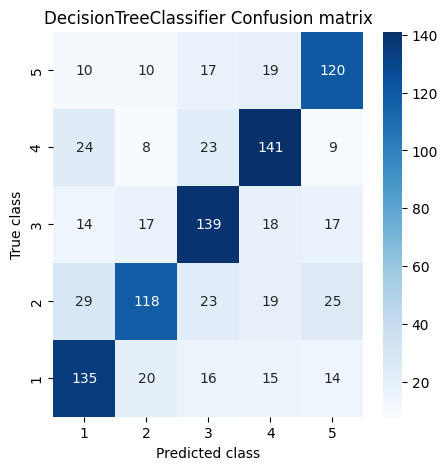

In [31]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
import joblib
import os

model_path = 'DecisionTreeClassifier.pkl'

# ---------------------------------------------------
# 1. Convert all object/string columns to numeric
# ---------------------------------------------------
def encode_dataframe(df):
    df = df.copy()
    for col in df.select_dtypes(include=['object']):
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
    return df

x_train_encoded = encode_dataframe(x_train)
x_test_encoded  = encode_dataframe(x_test)

# ---------------------------------------------------
# 2. Try loading existing model
# ---------------------------------------------------
load_model = False
if os.path.exists(model_path):
    try:
        dt_model = joblib.load(model_path)
        _ = dt_model.predict(x_test_encoded)  # test compatibility
        load_model = True
        print("Loaded existing Decision Tree model.")
    except:
        print("Decision Tree model mismatch → Retraining...")
        load_model = False


# ---------------------------------------------------
# 3. Train fresh model if needed
# ---------------------------------------------------
if not load_model:
    dt_model = DecisionTreeClassifier()
    dt_model.fit(x_train_encoded, y_train)

    joblib.dump(dt_model, model_path)
    print("Decision Tree model trained and saved.")


# ---------------------------------------------------
# 4. Predict
# ---------------------------------------------------
predict = dt_model.predict(x_test_encoded)

# ---------------------------------------------------
# 5. Evaluate performance
# ---------------------------------------------------
PerformanceMetrics("DecisionTreeClassifier", predict, y_test)


Loading saved model & encoder...
RandomForestClassifier Accuracy    : 97.5
RandomForestClassifier Precision   : 97.44689779695183
RandomForestClassifier Recall      : 97.54590318503014
RandomForestClassifier FSCORE      : 97.46429697125498

RandomForestClassifier Classification Report:

              precision    recall  f1-score   support

           1       0.99      0.96      0.98       200
           2       0.99      0.98      0.98       214
           3       0.98      0.96      0.97       205
           4       0.97      0.99      0.98       205
           5       0.93      0.99      0.96       176

    accuracy                           0.97      1000
   macro avg       0.97      0.98      0.97      1000
weighted avg       0.98      0.97      0.98      1000



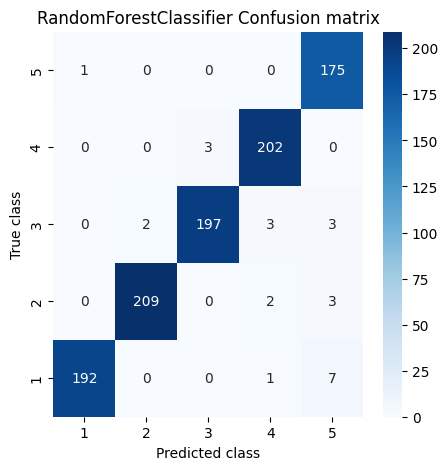

In [41]:
import os
import joblib
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier


model_path = "RandomForestClassifier.pkl"
encoder_path = "ordinal_encoder.pkl"

def encode_with_ordinal(x_train, x_test):
    cat_cols = x_train.select_dtypes(include=['object', 'string']).columns.tolist()
    enc = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )

    if len(cat_cols) > 0:
        x_train[cat_cols] = enc.fit_transform(x_train[cat_cols].astype(str))
        x_test[cat_cols] = enc.transform(x_test[cat_cols].astype(str))

    return x_train, x_test, enc


try:
    if os.path.exists(model_path) and os.path.exists(encoder_path):
        print("Loading saved model & encoder...")

        rf_model = joblib.load(model_path)
        encoder = joblib.load(encoder_path)

        cat_cols = x_test.select_dtypes(include=['object', 'string']).columns.tolist()

        if len(cat_cols) > 0:
            x_test[cat_cols] = encoder.transform(x_test[cat_cols].astype(str))

        preds = rf_model.predict(x_test)
        PerformanceMetrics("RandomForestClassifier", preds, y_test)

    else:
        raise FileNotFoundError("Saved model or encoder missing.")

except Exception as e:
    print("Error occurred, retraining model:", e)

    # Delete old model if exists
    if os.path.exists(model_path):
        os.remove(model_path)
    if os.path.exists(encoder_path):
        os.remove(encoder_path)

    # Encode again
    x_train_encoded, x_test_encoded, encoder = encode_with_ordinal(
        x_train.copy(), x_test.copy()
    )

    # Train new model
    rf_model = RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
    rf_model.fit(x_train_encoded, y_train)

    # Predict
    preds = rf_model.predict(x_test_encoded)

    # Save model & encoder
    joblib.dump(rf_model, model_path)
    joblib.dump(encoder, encoder_path)

    print("New model & encoder saved.")

    PerformanceMetrics("RandomForestClassifier", preds, y_test)


In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import plot_model
import joblib
import os
import seaborn as sns
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from itertools import cycle
import matplotlib.pyplot as plt


In [4]:
df=pd.read_csv("PriorityDataset_1.csv")
df

,Vehicle ID,Speed (km/h),"GPS Location (Lat, Long)",Signal Strength (dBm),Packet Delay (ms),Congestion Level (%),Available Bandwidth (MHz),Contention Window Size,RSU Connection (Yes/No),Traffic Density (vehicles/km²),Priority Level (1-5)
0,V0103,23,"(-1.4919, 104.766)",-55,34,57,22,46,Yes,19,4
1,V0436,88,"(-29.2844, 139.1703)",-52,9,61,14,41,Yes,93,2
2,V0861,37,"(-30.4282, -117.4462)",-79,17,21,35,46,Yes,23,1
3,V0271,90,"(11.9613, -114.2802)",-85,25,76,24,33,Yes,11,4
4,V0107,117,"(8.7171, 2.9953)",-72,23,77,48,42,Yes,38,5
...,...,...,...,...,...,...,...,...,...,...,...
4995,V0290,57,"(-48.8052, 56.5931)",-83,34,12,24,44,Yes,32,1
4996,V0295,35,"(-9.8659, -96.0506)",-52,50,61,43,43,No,40,2
4997,V0451,102,"(79.5828, 175.25)",-64,26,80,12,13,Yes,27,1
4998,V0904,66,"(88.6695, 53.1574)",-71,23,75,6,36,Yes,86,2


In [5]:
df.shape

(5000, 11)

In [6]:
df.columns

Index(['Vehicle ID', 'Speed (km/h)', 'GPS Location (Lat, Long)',
       'Signal Strength (dBm)', 'Packet Delay (ms)', 'Congestion Level (%)',
       'Available Bandwidth (MHz)', 'Contention Window Size',
       'RSU Connection (Yes/No)', 'Traffic Density (vehicles/km²)',
       'Priority Level (1-5)'],
      dtype='object')

In [8]:
df.isnull().sum()

Vehicle ID                        0
Speed (km/h)                      0
GPS Location (Lat, Long)          0
Signal Strength (dBm)             0
Packet Delay (ms)                 0
Congestion Level (%)              0
Available Bandwidth (MHz)         0
Contention Window Size            0
RSU Connection (Yes/No)           0
Traffic Density (vehicles/km²)    0
Priority Level (1-5)              0
dtype: int64

In [9]:
df.describe()

,Speed (km/h),Signal Strength (dBm),Packet Delay (ms),Congestion Level (%),Available Bandwidth (MHz),Contention Window Size,Traffic Density (vehicles/km²),Priority Level (1-5)
count,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000
mean,70.256600,-69.76320,27.617600,49.172000,26.516400,29.670200,55.22520,3.028400
std,28.286053,11.95492,13.264621,29.230903,13.036415,11.679894,26.66963,1.404702
min,20.000000,-90.00000,5.000000,0.000000,5.000000,10.000000,10.00000,1.000000
25%,45.000000,-80.00000,16.000000,24.000000,15.000000,20.000000,32.00000,2.000000
50%,70.000000,-70.00000,28.000000,49.000000,26.000000,29.000000,56.00000,3.000000
75%,94.000000,-59.00000,39.000000,74.000000,37.000000,40.000000,78.00000,4.000000
max,120.000000,-50.00000,50.000000,100.000000,50.000000,50.000000,100.00000,5.000000


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   Vehicle ID                      5000 non-null   object
 1   Speed (km/h)                    5000 non-null   int64 
 2   GPS Location (Lat, Long)        5000 non-null   object
 3   Signal Strength (dBm)           5000 non-null   int64 
 4   Packet Delay (ms)               5000 non-null   int64 
 5   Congestion Level (%)            5000 non-null   int64 
 6   Available Bandwidth (MHz)       5000 non-null   int64 
 7   Contention Window Size          5000 non-null   int64 
 8   RSU Connection (Yes/No)         5000 non-null   object
 9   Traffic Density (vehicles/km²)  5000 non-null   int64 
 10  Priority Level (1-5)            5000 non-null   int64 
dtypes: int64(8), object(3)
memory usage: 429.8+ KB


In [19]:
df.duplicated().sum()

4011

In [21]:
# Split into features and target
X = df.drop('Priority Level (1-5)', axis=1)
y = df['Priority Level (1-5)']
# Normalize the features
#scaler = StandardScaler()
#X_scaled = scaler.fit_transform(X)
# Split into train-test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [22]:
X_train

,Vehicle ID,Speed (km/h),"GPS Location (Lat, Long)",Signal Strength (dBm),Packet Delay (ms),Congestion Level (%),Available Bandwidth (MHz),Contention Window Size,RSU Connection (Yes/No),Traffic Density (vehicles/km²)
4227,V0156,104,"(-54.3652, 115.0533)",-60,28,6,19,48,No,35
4676,V0395,43,"(-76.5166, -42.7983)",-57,43,77,8,16,Yes,86
800,V0506,90,"(18.4261, 81.4944)",-73,20,53,33,43,Yes,42
3671,V0111,40,"(-86.752, -105.0852)",-62,15,36,19,25,No,22
4193,V0190,32,"(39.1745, 85.5968)",-74,7,50,50,46,Yes,26
...,...,...,...,...,...,...,...,...,...,...
4426,V0984,94,"(-49.6835, 25.3545)",-78,19,79,5,39,No,69
466,V0220,92,"(61.7776, 86.1239)",-70,50,20,44,50,No,21
3092,V0554,53,"(-43.5612, 7.7808)",-53,14,36,49,39,No,76
3772,V0915,109,"(-71.5389, 41.3942)",-57,6,76,22,25,Yes,20


In [23]:
y_train

4227    1
4676    2
800     5
3671    1
4193    1
       ..
4426    3
466     4
3092    2
3772    2
860     2
Name: Priority Level (1-5), Length: 4000, dtype: int64

Accuracy: 98.00%
Precision: 97.99%
Recall: 98.03%
F1 Score: 97.98%

Classification Report:
              precision    recall  f1-score   support

           1       0.99      0.96      0.97       200
           2       0.99      0.99      0.99       214
           3       1.00      0.96      0.98       205
           4       0.96      1.00      0.98       205
           5       0.96      0.99      0.98       176

    accuracy                           0.98      1000
   macro avg       0.98      0.98      0.98      1000
weighted avg       0.98      0.98      0.98      1000



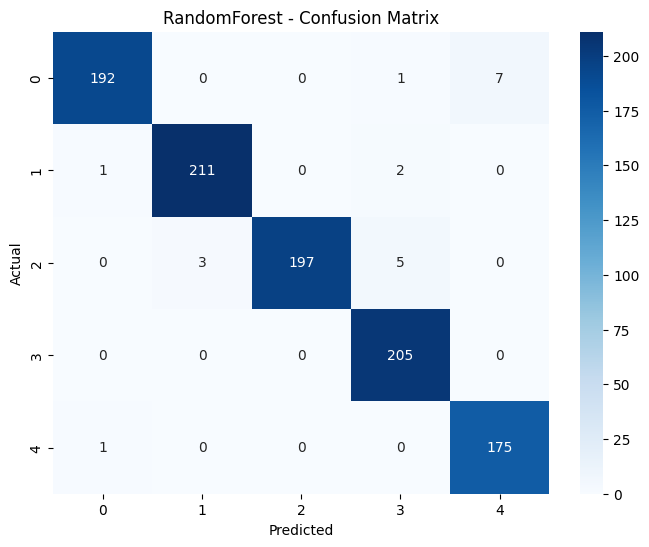

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
from sklearn.ensemble import RandomForestClassifier

# ---------------------------
# 1. Load Dataset
# ---------------------------
df=pd.read_csv("PriorityDataset_1.csv")

# 2. Define Target Column
# ---------------------------
target_col = "Priority Level (1-5)"

# ---------------------------
# 3. Separate Features & Target
# ---------------------------
X = df.drop(target_col, axis=1)
y = df[target_col]

# ---------------------------
# 4. Encode Categorical Columns
# ---------------------------
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)

X[cat_cols] = encoder.fit_transform(X[cat_cols])

# ---------------------------
# 5. Train-Test Split
# ---------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ---------------------------
# 6. Train the Model
# ---------------------------
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    random_state=42
)

model.fit(X_train, y_train)

# ---------------------------
# 7. Predictions
# ---------------------------
y_pred = model.predict(X_test)

# ---------------------------
# 8. Metrics
# ---------------------------
acc = accuracy_score(y_test, y_pred) * 100
prec = precision_score(y_test, y_pred, average='macro') * 100
rec = recall_score(y_test, y_pred, average='macro') * 100
f1 = f1_score(y_test, y_pred, average='macro') * 100

print(f"Accuracy: {acc:.2f}%")
print(f"Precision: {prec:.2f}%")
print(f"Recall: {rec:.2f}%")
print(f"F1 Score: {f1:.2f}%")

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# ---------------------------
# 9. Confusion Matrix
# ---------------------------
plt.figure(figsize=(8,6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, cmap="Blues", fmt="g")
plt.title("RandomForest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [34]:
def Calculate_Metrics(algorithm, y_pred, y_test, y_score):
    global metrics_df

    acc = accuracy_score(y_test, y_pred) * 100
    prec = precision_score(y_test, y_pred, zero_division=0) * 100
    rec = recall_score(y_test, y_pred) * 100
    f1 = f1_score(y_test, y_pred) * 100

    metrics_df.loc[len(metrics_df)] = [algorithm, acc, prec, rec, f1]

    print(f"\n--- {algorithm} RESULTS ---")
    print(f"Accuracy  : {acc:.2f}%")
    print(f"Precision : {prec:.2f}%")
    print(f"Recall    : {rec:.2f}%")
    print(f"F1 Score  : {f1:.2f}%")


In [35]:
test_data = df.sample(20)
test_data

,Vehicle ID,Speed (km/h),"GPS Location (Lat, Long)",Signal Strength (dBm),Packet Delay (ms),Congestion Level (%),Available Bandwidth (MHz),Contention Window Size,RSU Connection (Yes/No),Traffic Density (vehicles/km²),Priority Level (1-5)
4489,V0549,61,"(26.5579, 78.3332)",-73,22,40,26,44,No,40,5
1986,V0782,59,"(-44.3475, -22.5769)",-72,44,74,40,36,No,89,2
1845,V0027,90,"(-54.4595, 21.5988)",-66,48,62,23,47,No,88,4
1988,V0629,96,"(-38.1564, -17.9779)",-90,42,36,24,45,No,87,4
2507,V0926,33,"(-87.9989, -36.4143)",-57,49,72,21,23,No,12,3
4804,V0613,90,"(-29.5507, -170.035)",-80,41,57,44,25,No,71,5
1887,V0310,120,"(55.1363, 55.7818)",-75,14,34,25,39,No,51,1
1665,V0032,44,"(-67.8401, -47.7844)",-69,46,58,41,30,No,26,5
3889,V0725,29,"(-67.3383, 69.895)",-69,10,73,24,16,No,42,1
4402,V0820,82,"(-89.8055, -58.673)",-64,43,38,47,17,No,65,2


In [36]:
test_data.drop('Priority Level (1-5)', inplace = True, axis = 1)

In [37]:
test_data


,Vehicle ID,Speed (km/h),"GPS Location (Lat, Long)",Signal Strength (dBm),Packet Delay (ms),Congestion Level (%),Available Bandwidth (MHz),Contention Window Size,RSU Connection (Yes/No),Traffic Density (vehicles/km²)
4489,V0549,61,"(26.5579, 78.3332)",-73,22,40,26,44,No,40
1986,V0782,59,"(-44.3475, -22.5769)",-72,44,74,40,36,No,89
1845,V0027,90,"(-54.4595, 21.5988)",-66,48,62,23,47,No,88
1988,V0629,96,"(-38.1564, -17.9779)",-90,42,36,24,45,No,87
2507,V0926,33,"(-87.9989, -36.4143)",-57,49,72,21,23,No,12
4804,V0613,90,"(-29.5507, -170.035)",-80,41,57,44,25,No,71
1887,V0310,120,"(55.1363, 55.7818)",-75,14,34,25,39,No,51
1665,V0032,44,"(-67.8401, -47.7844)",-69,46,58,41,30,No,26
3889,V0725,29,"(-67.3383, 69.895)",-69,10,73,24,16,No,42
4402,V0820,82,"(-89.8055, -58.673)",-64,43,38,47,17,No,65


In [41]:
# ------------------------------------------------------------
# 1️⃣ IMPORTS
# ------------------------------------------------------------
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from keras.models import Sequential
from keras.layers import Dense, Input

# ------------------------------------------------------------
# 2️⃣ LOAD DATA
# ------------------------------------------------------------
df=pd.read_csv("PriorityDataset_1.csv")

# ------------------------------------------------------------
# 3️⃣ SEPARATE FEATURES + TARGET
# ------------------------------------------------------------
target_col = "Priority Level (1-5)"     # change if your target is different

X = df.drop(target_col, axis=1)
y = df[target_col]

# ------------------------------------------------------------
# 4️⃣ TRAIN–TEST SPLIT
# ------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# --------


In [44]:
test_data["Priority Level (1-5)"] = [categories[i] for i in final]
test_data

NameError: name 'final' is not defined